## 1. Setup

In [9]:
import json, warnings, zipfile, joblib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.base import clone
from sklearn.metrics import (average_precision_score, classification_report, ConfusionMatrixDisplay,
                             precision_recall_curve, roc_auc_score, RocCurveDisplay, PrecisionRecallDisplay,
                             recall_score, precision_score)
from sklearn.model_selection import (StratifiedKFold, cross_validate, cross_val_predict,
                                     train_test_split, GridSearchCV)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
SEED = 42
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)
plt.rcParams["figure.dpi"] = 90
print("Setup complete ✔")

Setup complete ✔


### Shared helper module (`features.py`)
Feature engineering, the target definition, risk tiers and the plain-language *"key factors"* rules live in one small module so the
**notebook, `train.py` and the Streamlit app use identical logic**. The cell writes it if it is missing.

In [10]:
from pathlib import Path
if not Path('features.py').exists():
    Path('features.py').write_text('''"""Shared feature engineering + business rules (notebook, trainer and Streamlit app all use this)."""
import numpy as np
import pandas as pd

DATA_FILE = "student_performance_data.csv"

# Raw columns the model is allowed to see (attendance, study habits, support context)
BASE_FEATURES = ["Age", "Absences", "StudyTimeWeekly", "Tutoring", "ParentalSupport",
                 "Extracurricular", "Sports", "Music", "Volunteering"]
ENGINEERED = ["activities_count", "high_absence", "low_study", "absence_study_ratio"]
MODEL_FEATURES = BASE_FEATURES + ENGINEERED
REQUIRED_COLUMNS = BASE_FEATURES

# Never used as model inputs: only for the fairness audit
AUDIT_COLUMNS = ["Gender", "Ethnicity", "ParentalEducation"]

HIGH_ABSENCE = 15      # absences per year considered high
LOW_STUDY = 5          # study hours / week considered low

SUPPORT_LABELS = {0: "None", 1: "Low", 2: "Moderate", 3: "High", 4: "Very high"}


def make_target(df: pd.DataFrame) -> pd.Series:
    """needs_support = 1 when GradeClass == 4 (F, i.e. GPA < 2.0)."""
    return (df["GradeClass"] == 4).astype(int)


def add_features(df: pd.DataFrame) -> pd.DataFrame:
    d = df.copy()
    d["activities_count"] = d[["Extracurricular", "Sports", "Music", "Volunteering"]].sum(axis=1)
    d["high_absence"] = (d["Absences"] >= HIGH_ABSENCE).astype(int)
    d["low_study"] = (d["StudyTimeWeekly"] < LOW_STUDY).astype(int)
    d["absence_study_ratio"] = d["Absences"] / (d["StudyTimeWeekly"] + 1)
    return d


def risk_tier(p, high_thr, medium_thr):
    return np.where(p >= high_thr, "High", np.where(p >= medium_thr, "Medium", "Low"))


def explain_row(r) -> str:
    """Plain-language key factors for a student (NaN-safe)."""
    out = []
    a, s = r.get("Absences", np.nan), r.get("StudyTimeWeekly", np.nan)
    if a >= HIGH_ABSENCE:
        out.append(f"{int(a)} absences (high)")
    elif a >= 10:
        out.append(f"{int(a)} absences (rising)")
    if s < LOW_STUDY:
        out.append(f"Only {s:.1f} study hrs/week")
    elif s < 8:
        out.append(f"Moderate study time ({s:.1f} hrs/week)")
    if r.get("ParentalSupport", np.nan) <= 1:
        out.append("Low parental support")
    if r.get("Tutoring", np.nan) == 0 and (a >= HIGH_ABSENCE or s < LOW_STUDY):
        out.append("No tutoring in place")
    if r.get("activities_count", 1) == 0:
        out.append("No extracurricular engagement")
    return "; ".join(out) if out else "No single dominant factor"
''')

from features import (MODEL_FEATURES, BASE_FEATURES, REQUIRED_COLUMNS, AUDIT_COLUMNS, add_features,
                      make_target, risk_tier, explain_row)
print(len(MODEL_FEATURES), 'model features:', MODEL_FEATURES)
print('audit-only columns (never fed to model):', AUDIT_COLUMNS)

13 model features: ['Age', 'Absences', 'StudyTimeWeekly', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering', 'activities_count', 'high_absence', 'low_study', 'absence_study_ratio']
audit-only columns (never fed to model): ['Gender', 'Ethnicity', 'ParentalEducation']


## 2. Load the Kaggle dataset
Put the CSV next to this notebook (or keep `archive.zip` there — it is extracted automatically).

| Column | Meaning (per the Kaggle description) | Role |
|---|---|---|
| `StudentID` | identifier (1001–3392) | ❌ dropped |
| `Age` | 15–18 | ✅ feature |
| `Gender` | 0 = male, 1 = female | 🔍 audit only |
| `Ethnicity` | 0 Caucasian, 1 African American, 2 Asian, 3 Other | 🔍 audit only |
| `ParentalEducation` | 0 none … 4 higher | 🔍 audit only (socio-economic proxy) |
| `StudyTimeWeekly` | study hours / week (0–20) | ✅ |
| `Absences` | absences in the year (0–29) — our **attendance** signal | ✅ |
| `Tutoring` | 0 no / 1 yes | ✅ |
| `ParentalSupport` | 0 none … 4 very high | ✅ |
| `Extracurricular`, `Sports`, `Music`, `Volunteering` | 0/1 | ✅ |
| `GPA` | 0–4 | ❌ **outcome → leakage** |
| `GradeClass` | 0 = A, 1 = B, 2 = C, 3 = D, 4 = F | 🎯 target source |

In [11]:
import os
from pathlib import Path
import pandas as pd

# ── 1. Mount Google Drive (only runs inside Google Colab) ────────────────────
try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# ── 2. 👉 EDIT THIS: full path to the CSV file in your Drive ────────────────
DATA_PATH = Path('/content/drive/MyDrive/Student_performance_data _.csv')

# Where model.joblib, model_meta.json, etc. will be saved (created automatically)
OUT_DIR = DATA_PATH.parent / 'student_support_outputs'

# ── 3. Check the file exists; if not, show what is actually in that folder ───
if not DATA_PATH.is_file():
    folder = DATA_PATH.parent
    print(f'❌ File not found: {DATA_PATH}')
    if folder.exists():
        print(f'\nFiles in {folder}:')
        for p in sorted(folder.iterdir())[:40]:
            print('  ', p.name)
        print('\nCopy the exact file name (watch for spaces, e.g. "..._data _.csv") into DATA_PATH.')
    else:
        print(f'Folder does not exist: {folder}  (is Drive mounted?)')
    raise FileNotFoundError(DATA_PATH)

# ── 4. Save outputs in Drive so they survive after Colab disconnects ─────────
if IN_COLAB:
    OUT_DIR.mkdir(exist_ok=True)
    os.chdir(OUT_DIR)

raw = pd.read_csv(DATA_PATH)
print('Loaded', DATA_PATH, '->', raw.shape)
raw.head(8)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loaded /content/drive/MyDrive/Student_performance_data _.csv -> (2392, 15)


,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0
5,1006,18,0,0,1,8.191219,0,0,1,1,0,0,0,3.084184,1.0
6,1007,15,0,1,1,15.601680,10,0,3,0,1,0,0,2.748237,2.0
7,1008,15,1,1,4,15.424496,22,1,1,1,0,0,0,1.360143,4.0


In [12]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 3. Data validation

In [13]:
print('Missing values :', int(raw.isna().sum().sum()))
print('Duplicate rows :', int(raw.duplicated().sum()))
print('Duplicate IDs  :', int(raw.StudentID.duplicated().sum()))
raw.drop(columns='StudentID').describe().T.round(2)

Missing values : 0
Duplicate rows : 0
Duplicate IDs  : 0


,count,mean,std,min,25%,50%,75%,max
Age,2392.0,16.47,1.12,15.0,15.00,16.00,17.00,18.00
Gender,2392.0,0.51,0.50,0.0,0.00,1.00,1.00,1.00
Ethnicity,2392.0,0.88,1.03,0.0,0.00,0.00,2.00,3.00
ParentalEducation,2392.0,1.75,1.00,0.0,1.00,2.00,2.00,4.00
StudyTimeWeekly,2392.0,9.77,5.65,0.0,5.04,9.71,14.41,19.98
Absences,2392.0,14.54,8.47,0.0,7.00,15.00,22.00,29.00
Tutoring,2392.0,0.30,0.46,0.0,0.00,0.00,1.00,1.00
ParentalSupport,2392.0,2.12,1.12,0.0,1.00,2.00,3.00,4.00
Extracurricular,2392.0,0.38,0.49,0.0,0.00,0.00,1.00,1.00
Sports,2392.0,0.30,0.46,0.0,0.00,0.00,1.00,1.00


### Does `GradeClass` really follow GPA? (label-quality check)
`GradeClass` should map to GPA bands (A ≥ 3.5, B ≥ 3.0, C ≥ 2.5, D ≥ 2.0, F < 2.0). We verify that before trusting it as a label.

In [14]:
band = np.select([raw.GPA >= 3.5, raw.GPA >= 3.0, raw.GPA >= 2.5, raw.GPA >= 2.0], [0, 1, 2, 3], 4)
print(f'GradeClass agrees with its GPA band in {(band == raw.GradeClass).mean():.1%} of rows  '
      f'-> ~{1 - (band == raw.GradeClass).mean():.0%} label noise (caps achievable accuracy)')
print(f"Correlation Absences vs GPA: {raw[['Absences','GPA']].corr().iloc[0,1]:.2f}   <- GPA is almost an outcome of attendance; never use it as an input")
pd.crosstab(pd.cut(raw.GPA, [-.01, 1, 1.5, 2, 2.5, 3, 3.5, 4.01]), raw.GradeClass.map({0:'A',1:'B',2:'C',3:'D',4:'F'}))

GradeClass agrees with its GPA band in 93.0% of rows  -> ~7% label noise (caps achievable accuracy)
Correlation Absences vs GPA: -0.92   <- GPA is almost an outcome of attendance; never use it as an input


GradeClass,A,B,C,D,F
GPA,,,,,
"(-0.01, 1.0]",5,7,5,10,441
"(1.0, 1.5]",5,6,11,7,351
"(1.5, 2.0]",6,15,1,7,397
"(2.0, 2.5]",9,7,9,375,12
"(2.5, 3.0]",10,3,360,7,5
"(3.0, 3.5]",1,229,3,7,4
"(3.5, 4.01]",71,2,2,1,1


## 4. Define the target
Students with grade **F (GPA < 2.0)** are the ones who need academic support — the usual academic-probation line.
(Want a broader net? change `make_target` in `features.py` to `GradeClass >= 3` to include D grades.)

In [15]:
y_all = make_target(raw)
print(f"needs_support = 1 for {y_all.sum()} of {len(y_all)} students ({y_all.mean():.1%})  -> roughly balanced classes")
raw['needs_support'] = y_all
raw.groupby('needs_support')[['Absences', 'StudyTimeWeekly', 'ParentalSupport', 'Tutoring', 'GPA']].mean().round(2)

needs_support = 1 for 1211 of 2392 students (50.6%)  -> roughly balanced classes


,Absences,StudyTimeWeekly,ParentalSupport,Tutoring,GPA
needs_support,,,,,
0,8.14,10.37,2.24,0.33,2.62
1,20.79,9.18,2.01,0.27,1.21


## 5. Exploratory data analysis

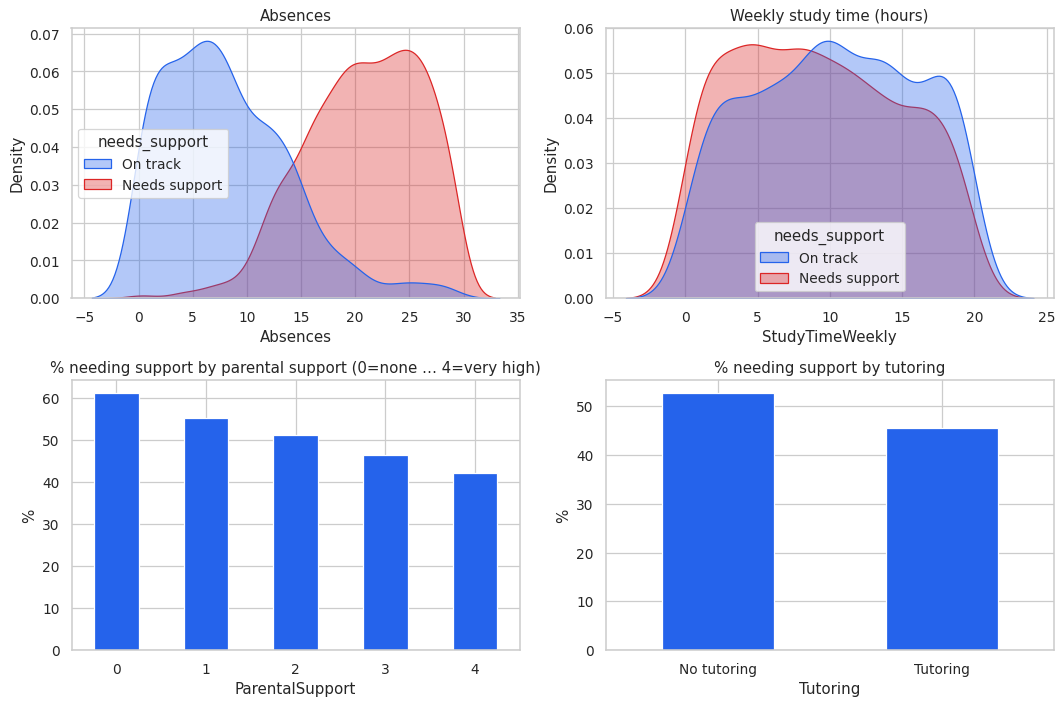

In [16]:
lab = raw['needs_support'].map({0: 'On track', 1: 'Needs support'})
fig, ax = plt.subplots(2, 2, figsize=(12, 8))
pal = ['#2563eb', '#dc2626']
sns.kdeplot(data=raw, x='Absences', hue=lab, fill=True, common_norm=False, alpha=.35, ax=ax[0, 0], palette=pal)
ax[0, 0].set_title('Absences')
sns.kdeplot(data=raw, x='StudyTimeWeekly', hue=lab, fill=True, common_norm=False, alpha=.35, ax=ax[0, 1], palette=pal)
ax[0, 1].set_title('Weekly study time (hours)')
(raw.groupby('ParentalSupport')['needs_support'].mean() * 100).plot.bar(ax=ax[1, 0], color='#2563eb', rot=0)
ax[1, 0].set_title('% needing support by parental support (0=none … 4=very high)'); ax[1, 0].set_ylabel('%')
(raw.groupby('Tutoring')['needs_support'].mean() * 100).rename({0: 'No tutoring', 1: 'Tutoring'}).plot.bar(ax=ax[1, 1], color='#2563eb', rot=0)
ax[1, 1].set_title('% needing support by tutoring'); ax[1, 1].set_ylabel('%')
plt.tight_layout(); plt.show()

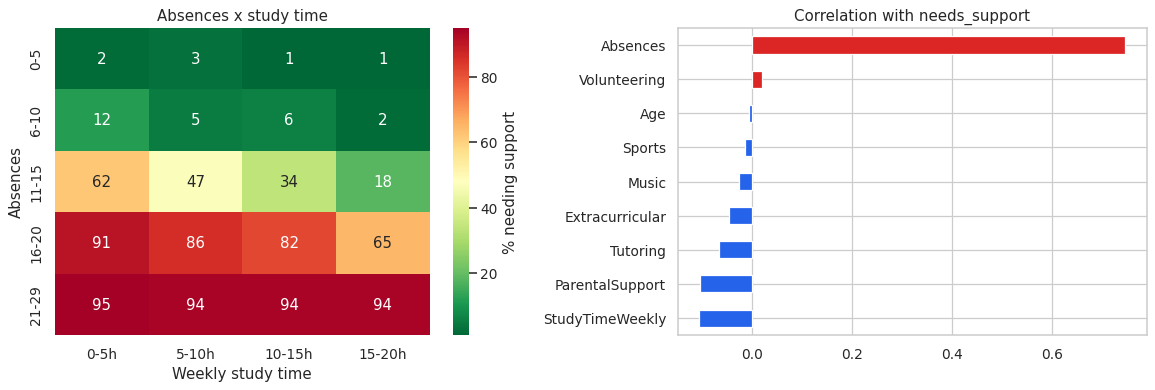

In [17]:
ab = pd.cut(raw.Absences, [-1, 5, 10, 15, 20, 30], labels=['0-5', '6-10', '11-15', '16-20', '21-29'])
st_ = pd.cut(raw.StudyTimeWeekly, [-.1, 5, 10, 15, 20], labels=['0-5h', '5-10h', '10-15h', '15-20h'])
heat = (raw.pivot_table(index=ab, columns=st_, values='needs_support', aggfunc='mean', observed=True) * 100).round(0)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.heatmap(heat, annot=True, fmt='.0f', cmap='RdYlGn_r', ax=ax[0], cbar_kws={'label': '% needing support'})
ax[0].set_title('Absences x study time'); ax[0].set_xlabel('Weekly study time'); ax[0].set_ylabel('Absences')
corr = raw[BASE_FEATURES + ['needs_support']].corr()['needs_support'].drop('needs_support').sort_values()
corr.plot.barh(ax=ax[1], color=np.where(corr > 0, '#dc2626', '#2563eb')); ax[1].set_title('Correlation with needs_support')
plt.tight_layout(); plt.show()

**Takeaways:** attendance is by far the dominant signal — students needing support average ~21 absences versus ~8 for those on track — while
study time and parental support add smaller effects and activities/tutoring show little separation. Roughly half of all students are in the
positive class, so accuracy is meaningful here, but we still focus on recall and PR-AUC.

## 6. Feature engineering, split & preprocessing
New features: `activities_count`, `high_absence` (≥ 15), `low_study` (< 5 h), `absence_study_ratio`.
We **split first** (stratified 80/20) so the imputer/scaler learn only from training data. `GPA`, `GradeClass`, `StudentID`,
`Gender`, `Ethnicity` and `ParentalEducation` are **not** inputs.

In [18]:
data = add_features(raw)
X, y = data[MODEL_FEATURES], data['needs_support']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
print(f'Train {X_train.shape} | positive rate {y_train.mean():.1%}')
print(f'Test  {X_test.shape} | positive rate {y_test.mean():.1%}')

def make_preprocessor():
    return ColumnTransformer([('num', Pipeline([('impute', SimpleImputer(strategy='median', add_indicator=True)),
                                                ('scale', StandardScaler())]), MODEL_FEATURES)])
make_preprocessor()

Train (1913, 13) | positive rate 50.6%
Test  (479, 13) | positive rate 50.7%


ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('impute',
                                                  SimpleImputer(add_indicator=True,
                                                                strategy='median')),
                                                 ('scale', StandardScaler())]),
                                 ['Age', 'Absences', 'StudyTimeWeekly',
                                  'Tutoring', 'ParentalSupport',
                                  'Extracurricular', 'Sports', 'Music',
                                  'Volunteering', 'activities_count',
                                  'high_absence', 'low_study',
                                  'absence_study_ratio'])])

## 7. Model comparison (5-fold stratified CV on the training set)
**ROC-AUC** measures ranking quality; **PR-AUC (average precision)** focuses on how well we find the students who need support.

In [19]:
models = {
    'Logistic Regression':    LogisticRegression(max_iter=2000, class_weight='balanced'),
    'Random Forest':          RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1,
                                                     class_weight='balanced_subsample', random_state=SEED),
    'Hist Gradient Boosting': HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=250, random_state=SEED),
}
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
rows = {}
for name, m in models.items():
    pipe = Pipeline([('prep', make_preprocessor()), ('clf', m)])
    r = cross_validate(pipe, X_train, y_train, cv=cv, scoring={'roc_auc': 'roc_auc', 'pr_auc': 'average_precision'})
    rows[name] = {'ROC-AUC': r['test_roc_auc'].mean(), 'ROC-AUC sd': r['test_roc_auc'].std(),
                  'PR-AUC': r['test_pr_auc'].mean(), 'PR-AUC sd': r['test_pr_auc'].std()}
cv_table = pd.DataFrame(rows).T.round(4).sort_values('PR-AUC', ascending=False)
best_name = cv_table.index[0]
print('Best by PR-AUC ->', best_name)
cv_table

Best by PR-AUC -> Logistic Regression


,ROC-AUC,ROC-AUC sd,PR-AUC,PR-AUC sd
Logistic Regression,0.9500,0.0126,0.9323,0.0208
Hist Gradient Boosting,0.9468,0.0100,0.9268,0.0162
Random Forest,0.9465,0.0105,0.9265,0.0152


### Hyper-parameter tuning of the best model (grid search, scored on PR-AUC)

In [20]:
param_grids = {
    'Logistic Regression':    {'clf__C': [0.01, 0.1, 1, 10]},
    'Random Forest':          {'clf__min_samples_leaf': [3, 5, 10], 'clf__max_depth': [None, 6, 10]},
    'Hist Gradient Boosting': {'clf__max_depth': [2, 3, 4], 'clf__learning_rate': [0.03, 0.05, 0.1], 'clf__max_iter': [150, 250]},
}
gs = GridSearchCV(Pipeline([('prep', make_preprocessor()), ('clf', models[best_name])]),
                  param_grids[best_name], scoring='average_precision', cv=cv, n_jobs=-1)
gs.fit(X_train, y_train)
best_pipe = gs.best_estimator_
print(f'Best params : {gs.best_params_}')
print(f'CV PR-AUC   : {gs.best_score_:.4f}  (before tuning: {cv_table.loc[best_name, "PR-AUC"]:.4f})')

Best params : {'clf__C': 10}
CV PR-AUC   : 0.9335  (before tuning: 0.9323)


### Choosing the decision threshold
0.5 is rarely right. Because **missing a student who needs help is worse than a false alarm**, we choose the threshold that maximises
**F2** (recall weighted 2× over precision) on *out-of-fold* training predictions — the test set stays untouched.

High-risk threshold (max F2): 0.239   |   Medium-risk threshold: 0.119


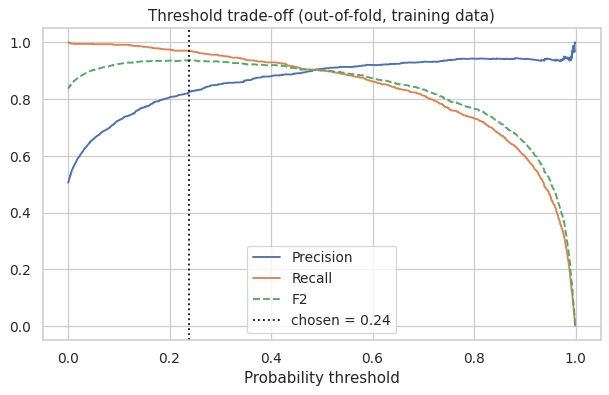

In [21]:
oof = cross_val_predict(clone(best_pipe), X_train, y_train, cv=cv, method='predict_proba')[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof)
f2 = 5 * prec[:-1] * rec[:-1] / np.clip(4 * prec[:-1] + rec[:-1], 1e-9, None)
HIGH_THR = float(thr[np.argmax(f2)])
MED_THR = HIGH_THR / 2
print(f'High-risk threshold (max F2): {HIGH_THR:.3f}   |   Medium-risk threshold: {MED_THR:.3f}')

plt.figure(figsize=(8, 4.5))
plt.plot(thr, prec[:-1], label='Precision'); plt.plot(thr, rec[:-1], label='Recall'); plt.plot(thr, f2, label='F2', ls='--')
plt.axvline(HIGH_THR, color='k', ls=':', label=f'chosen = {HIGH_THR:.2f}')
plt.xlabel('Probability threshold'); plt.legend(); plt.title('Threshold trade-off (out-of-fold, training data)')
plt.show()

## 8. Final evaluation on the untouched test set

{'roc_auc': np.float64(0.9281), 'pr_auc': np.float64(0.8952), 'recall': 0.9465, 'precision': 0.8156} 

               precision    recall  f1-score   support

     On track       0.93      0.78      0.85       236
Needs support       0.82      0.95      0.88       243

     accuracy                           0.86       479
    macro avg       0.87      0.86      0.86       479
 weighted avg       0.87      0.86      0.86       479



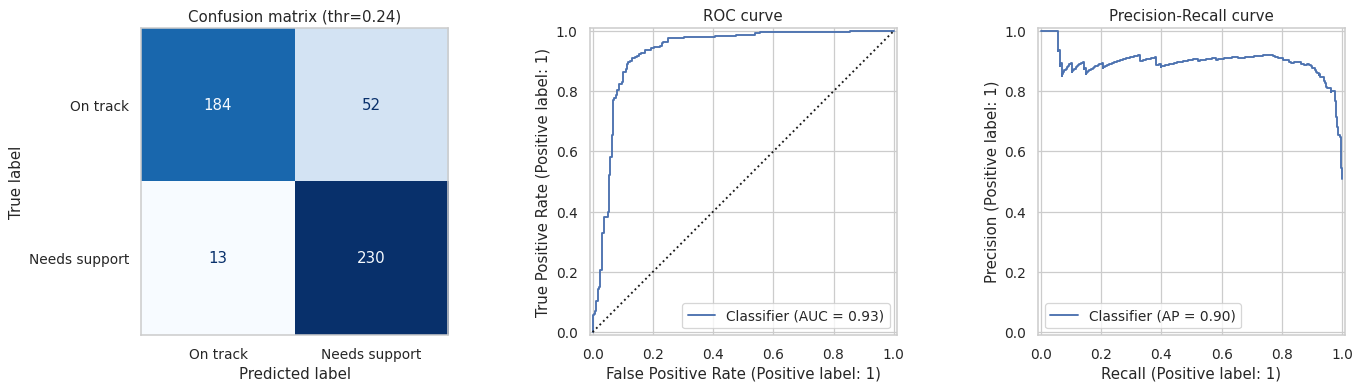

In [22]:
best_pipe.fit(X_train, y_train)
p_test = best_pipe.predict_proba(X_test)[:, 1]
y_pred = (p_test >= HIGH_THR).astype(int)

metrics = {'roc_auc': round(roc_auc_score(y_test, p_test), 4), 'pr_auc': round(average_precision_score(y_test, p_test), 4),
           'recall': round(recall_score(y_test, y_pred), 4), 'precision': round(precision_score(y_test, y_pred), 4)}
print(metrics, '\n')
print(classification_report(y_test, y_pred, target_names=['On track', 'Needs support']))

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=['On track', 'Needs support'], cmap='Blues', ax=ax[0], colorbar=False)
ax[0].set_title(f'Confusion matrix (thr={HIGH_THR:.2f})'); ax[0].grid(False)
RocCurveDisplay.from_predictions(y_test, p_test, ax=ax[1]); ax[1].plot([0, 1], [0, 1], 'k:'); ax[1].set_title('ROC curve')
PrecisionRecallDisplay.from_predictions(y_test, p_test, ax=ax[2]); ax[2].set_title('Precision-Recall curve')
plt.tight_layout(); plt.show()

### Capacity view — "we can only support the top *k*% of students"
Schools have limited tutoring capacity. Ranking students by risk shows how many genuinely at-risk students we reach for a given workload.

In [23]:
order = np.argsort(-p_test); ys = y_test.values[order]
pd.DataFrame([{
    'students supported (top %)': f'{int(k*100)}%', 'students': int(k * len(ys)),
    'at-risk students reached (recall)': ys[:int(k*len(ys))].sum() / ys.sum(),
    'precision in this group': ys[:int(k*len(ys))].mean(),
    'lift vs random': ys[:int(k*len(ys))].mean() / ys.mean(),
} for k in [0.10, 0.20, 0.30, 0.40, 0.50]]).round(3)

,students supported (top %),students,at-risk students reached (recall),precision in this group,lift vs random
0,10%,47,0.169,0.872,1.720
1,20%,95,0.354,0.905,1.784
2,30%,143,0.531,0.902,1.778
3,40%,191,0.720,0.916,1.806
4,50%,239,0.872,0.887,1.749


## 9. What drives the predictions?

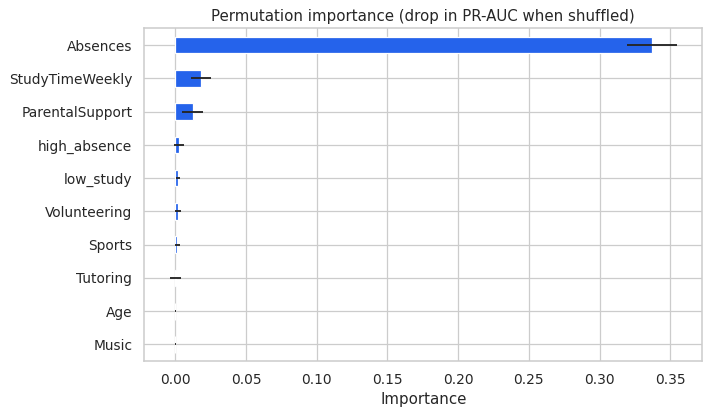

,importance
Absences,0.3369
StudyTimeWeekly,0.0180
ParentalSupport,0.0122
high_absence,0.0025
low_study,0.0020
Volunteering,0.0020


In [24]:
pi = permutation_importance(best_pipe, X_test, y_test, scoring='average_precision', n_repeats=15, random_state=SEED, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values()
err = pd.Series(pi.importances_std, index=X_test.columns)[imp.index]
imp.tail(10).plot.barh(xerr=err.tail(10), figsize=(8, 4.8), color='#2563eb')
plt.title('Permutation importance (drop in PR-AUC when shuffled)'); plt.xlabel('Importance'); plt.show()
imp.sort_values(ascending=False).head(6).round(4).to_frame('importance')

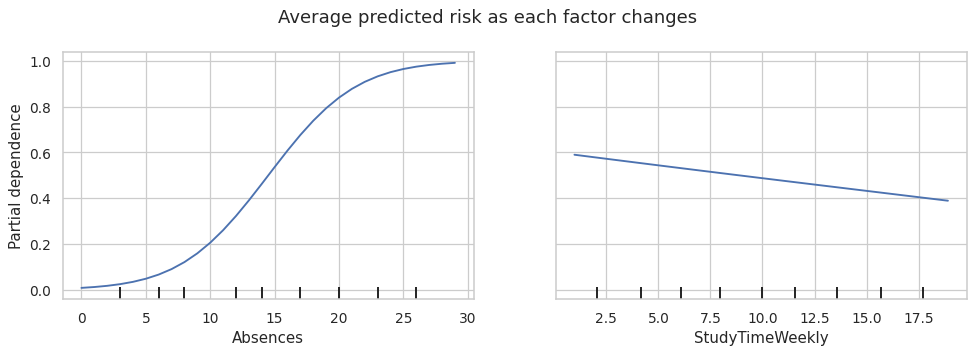

In [25]:
fig, ax = plt.subplots(figsize=(11, 4))
PartialDependenceDisplay.from_estimator(best_pipe, X_test.astype(float), ['Absences', 'StudyTimeWeekly'], kind='average', ax=ax)
fig.suptitle('Average predicted risk as each factor changes'); plt.tight_layout(); plt.show()

**`Absences` is overwhelmingly the strongest driver** (importance ≈ 0.34 vs ≈ 0.02 for the next feature), followed by study time and parental
support. The logic is easy to explain to staff — more absences and less study time → higher risk — which makes the flags trustworthy.
It also means the model is only as good as the attendance data feeding it.

## 10. Fairness audit
Gender, ethnicity and parental education were **not** inputs, but proxies can still produce unequal error rates. We compare **recall**
(are at-risk students being missed?), **false-positive rate** (unneeded flags) and **flag rate** across groups.

In [26]:
LABELS = {
    'Gender': {0: 'Male', 1: 'Female'},
    'Ethnicity': {0: 'Caucasian', 1: 'African American', 2: 'Asian', 3: 'Other'},
    'ParentalEducation': {0: 'None', 1: 'High school', 2: 'Some college', 3: "Bachelor's", 4: 'Higher'},
}
def group_report(by):
    grp = raw.loc[X_test.index, by].map(LABELS[by]); yp = pd.Series(y_pred, index=X_test.index); rows = []
    for g in grp.dropna().unique():
        idx = grp.index[grp == g]; yt, pp = y_test.loc[idx], yp.loc[idx]
        tp = ((yt == 1) & (pp == 1)).sum(); fn = ((yt == 1) & (pp == 0)).sum()
        fp = ((yt == 0) & (pp == 1)).sum(); tn = ((yt == 0) & (pp == 0)).sum()
        rows.append({by: g, 'n': len(idx), 'actual at-risk %': 100 * yt.mean(), 'flagged %': 100 * pp.mean(),
                     'recall (TPR)': tp / max(tp + fn, 1), 'false-positive rate': fp / max(fp + tn, 1), 'precision': tp / max(tp + fp, 1)})
    return pd.DataFrame(rows).sort_values(by).round(3).reset_index(drop=True)

for col in AUDIT_COLUMNS:
    print(f'\n=== {col} ==='); display(group_report(col))


=== Gender ===


,Gender,n,actual at-risk %,flagged %,recall (TPR),false-positive rate,precision
0,Female,255,52.549,60.000,0.948,0.215,0.830
1,Male,224,48.661,57.589,0.945,0.226,0.798



=== Ethnicity ===


,Ethnicity,n,actual at-risk %,flagged %,recall (TPR),false-positive rate,precision
0,African American,93,44.086,51.613,0.951,0.173,0.812
1,Asian,101,44.554,58.416,0.933,0.304,0.712
2,Caucasian,244,55.738,61.475,0.941,0.204,0.853
3,Other,41,51.220,60.976,1.000,0.200,0.840



=== ParentalEducation ===


,ParentalEducation,n,actual at-risk %,flagged %,recall (TPR),false-positive rate,precision
0,Bachelor's,78,46.154,56.410,0.917,0.262,0.750
1,High school,137,43.796,49.635,0.933,0.156,0.824
2,Higher,24,87.500,87.500,0.952,0.333,0.952
3,None,48,50.000,66.667,0.958,0.375,0.719
4,Some college,192,53.125,60.938,0.961,0.211,0.838


**What we see on this run:** recall is high for every group (≈ 93–100%), so at-risk students are not being missed more in any group. The main
gap is a **higher false-positive rate for Asian students (≈ 30% vs ≈ 17–22% for other ethnic groups)**, i.e. more unneeded flags, and for the
`None` parental-education group (≈ 38%). Several groups are small (e.g. *Higher* education n = 24), so those numbers are noisy.

**How to read it:** the worry is a large **recall gap** (the model misses at-risk students in one group) or a much higher
**false-positive rate** (one group gets many unneeded flags). Small groups (n < ~50) are noisy — treat them cautiously.
If gaps appear: review proxy features, gather more data, and discuss group-aware thresholds with stakeholders — never apply them silently.

## 11. Risk tiers & a teacher-friendly report

In [27]:
report = raw.loc[X_test.index, ['StudentID']].copy()
report['risk_probability'] = p_test.round(3)
report['risk_tier'] = risk_tier(p_test, HIGH_THR, MED_THR)
report['actually_needed_support'] = y_test.values
report['key_factors'] = data.loc[X_test.index].apply(explain_row, axis=1)

display((report.groupby('risk_tier')
         .agg(students=('StudentID', 'count'), actual_at_risk_rate=('actually_needed_support', 'mean'))
         .reindex(['High', 'Medium', 'Low']).round(3)))
print('\nTop 10 highest-risk students in the test set:')
report.sort_values('risk_probability', ascending=False).head(10).drop(columns='actually_needed_support')

,students,actual_at_risk_rate
risk_tier,,
High,282,0.816
Medium,41,0.195
Low,156,0.032



Top 10 highest-risk students in the test set:


,StudentID,risk_probability,risk_tier,key_factors
1724,2725,0.999,High,27 absences (high); Moderate study time (7.3 h...
2116,3117,0.999,High,29 absences (high); Low parental support; No t...
362,1363,0.999,High,29 absences (high); Low parental support; No e...
1499,2500,0.998,High,29 absences (high); Moderate study time (6.5 h...
158,1159,0.998,High,28 absences (high); Moderate study time (7.0 h...
1328,2329,0.998,High,29 absences (high); Only 3.1 study hrs/week; N...
725,1726,0.998,High,25 absences (high); Only 4.4 study hrs/week; L...
1039,2040,0.997,High,26 absences (high); Low parental support; No t...
1844,2845,0.997,High,27 absences (high); Moderate study time (5.5 h...
1266,2267,0.997,High,28 absences (high); Low parental support; No t...


## 12. Save model artefacts for deployment

In [28]:
meta = {'model': best_name, 'best_params': {k: (v if isinstance(v, (int, float, str, type(None))) else str(v)) for k, v in gs.best_params_.items()},
        'trained_at': pd.Timestamp.now().isoformat(timespec='seconds'),
        'target': 'needs_support = GradeClass == 4 (F, GPA < 2.0)',
        'high_threshold': round(HIGH_THR, 4), 'medium_threshold': round(MED_THR, 4),
        'metrics': metrics, 'cv_pr_auc': cv_table['PR-AUC'].round(4).to_dict(), 'features': MODEL_FEATURES}
joblib.dump(best_pipe, 'model.joblib')
Path('model_meta.json').write_text(json.dumps(meta, indent=2))

# demo cohort for the app: 60 unseen students (GradeClass kept so the app can show a back-test)
raw.loc[X_test.index[:60], ['StudentID'] + REQUIRED_COLUMNS + ['GradeClass']].to_csv('sample_upload.csv', index=False)
print('Saved: model.joblib, model_meta.json, sample_upload.csv')
print({k: v for k, v in meta.items() if k != 'features'})

Saved: model.joblib, model_meta.json, sample_upload.csv
{'model': 'Logistic Regression', 'best_params': {'clf__C': 10}, 'trained_at': '2026-11-27T05:22:54', 'target': 'needs_support = GradeClass == 4 (F, GPA < 2.0)', 'high_threshold': 0.2386, 'medium_threshold': 0.1193, 'metrics': {'roc_auc': np.float64(0.9281), 'pr_auc': np.float64(0.8952), 'recall': 0.9465, 'precision': 0.8156}, 'cv_pr_auc': {'Logistic Regression': 0.9323, 'Hist Gradient Boosting': 0.9268, 'Random Forest': 0.9265}}


## 13. Inference check — exactly what the Streamlit app does

In [29]:
loaded = joblib.load('model.joblib')
meta_loaded = json.loads(Path('model_meta.json').read_text())

def assess(student: dict) -> dict:
    row = add_features(pd.DataFrame([student]))
    p = float(loaded.predict_proba(row[MODEL_FEATURES])[:, 1][0])
    return {'risk_probability': round(p, 3),
            'risk_tier': str(risk_tier(np.array([p]), meta_loaded['high_threshold'], meta_loaded['medium_threshold'])[0]),
            'key_factors': explain_row(row.iloc[0])}

struggling = dict(Age=16, Absences=24, StudyTimeWeekly=3.0, Tutoring=0, ParentalSupport=1,
                  Extracurricular=0, Sports=0, Music=0, Volunteering=0)
thriving   = dict(Age=17, Absences=2, StudyTimeWeekly=16.0, Tutoring=1, ParentalSupport=4,
                  Extracurricular=1, Sports=1, Music=0, Volunteering=1)
print('Struggling student ->', assess(struggling))
print('Thriving student   ->', assess(thriving))

Struggling student -> {'risk_probability': 0.997, 'risk_tier': 'High', 'key_factors': '24 absences (high); Only 3.0 study hrs/week; Low parental support; No tutoring in place; No extracurricular engagement'}
Thriving student   -> {'risk_probability': 0.0, 'risk_tier': 'Low', 'key_factors': 'No single dominant factor'}


## 14. The Streamlit app

```
student_support_app/
├── app.py                          # Streamlit UI (single student • cohort upload • model info)
├── features.py                     # shared feature engineering + target + business rules
├── train.py                        # one-command re-training: python train.py
├── student_performance_data.csv    # your Kaggle dataset
├── model.joblib · model_meta.json  # trained pipeline, thresholds, metrics
├── sample_upload.csv               # demo cohort / CSV template
└── requirements.txt · Dockerfile · .streamlit/config.toml
```

**Run locally**
```bash
pip install -r requirements.txt
streamlit run app.py
```
**App features:** single-student form · CSV cohort scoring with High/Medium/Low tiers and key factors · optional back-test when the
upload has `GradeClass` · adjustable triage threshold · downloadable results · model & ethics page.

In [30]:
required = ['app.py', 'features.py', 'train.py', 'student_performance_data.csv', 'model.joblib', 'model_meta.json',
            'sample_upload.csv', 'requirements.txt', 'Dockerfile']
status = pd.DataFrame({'file': required, 'present': [Path(f).exists() for f in required]})
print('Deployment bundle complete ✔' if status.present.all() else 'Missing files!')
status

Missing files!


,file,present
0,app.py,False
1,features.py,True
2,train.py,False
3,student_performance_data.csv,False
4,model.joblib,True
5,model_meta.json,True
6,sample_upload.csv,True
7,requirements.txt,False
8,Dockerfile,False


## 15. Deployment

**A. Streamlit Community Cloud (free, easiest)** — push the folder to GitHub → <https://share.streamlit.io> → *New app* → pick `app.py` → *Deploy*.
If the cloud's scikit-learn version differs from training, the app **automatically retrains** from the CSV instead of crashing.

**B. Docker (any cloud / on-premise)**
```bash
docker build -t student-support .
docker run -p 8501:8501 student-support      # http://localhost:8501
```
Runs unchanged on Google Cloud Run, Azure Container Apps, AWS App Runner, Render, Railway or Fly.io.

**C. Hugging Face Spaces** — create a *Streamlit* Space and upload the same files.

### Limitations & next steps
- The Kaggle data is **synthetic** with ~7% noisy labels, and `Absences` drives the outcome strongly — real schools will be messier. Re-train on your own anonymised data (`python train.py`).
- Add real term-by-term attendance and assessment history for earlier, more actionable warnings.
- Track which interventions work (uplift modelling) and re-run the fairness audit every term.
- Put the app behind authentication and never upload names or direct identifiers.